# Dataset de comandos de voz y preprocesamiento

**Hitos 1 y 2: captura, acondicionamiento y revisión.** Las clases son reconocer, identificar y salir. H001 y H002 se emplearon para desarrollar el procedimiento; la evaluación final requerirá otras personas reservadas.

Este notebook consulta archivos. No graba, modifica metadatos, ajusta parámetros ni asigna particiones. Se entrega sin audios ni resultados incrustados. Los comandos de ejecución y la explicación completa están en `documentos/preprocesamiento_audio.md`.

Un archivo procesado no es automáticamente una muestra apta para entrenar. La revisión de la palabra y del recorte requiere escucha.

In [1]:
from pathlib import Path
from collections import Counter
import csv
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/audio_v1.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError("Abrir el notebook dentro de la raíz del proyecto o notebooks/.")
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))
from preprocesamiento_audio import leer_wav_pcm16

def leer_csv(ruta):
    if not ruta.exists():
        return []
    with ruta.open(encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))

capturas = leer_csv(RAIZ / "datos/audio/metadatos.csv")
actual = RAIZ / "datos/audio/procesados/actual.json"
procesados = []
referencia = None
if actual.exists():
    referencia = json.loads(actual.read_text(encoding="utf-8"))
    procesados = leer_csv(RAIZ / referencia["ruta_catalogo"])
print("Capturas:", len(capturas))
print("Versión activa:", referencia["version"] if referencia else "aún no se ejecutó el preprocesamiento")
print("Resultados en el catálogo activo:", len(procesados))
ids_procesados = {r["muestra_id"] for r in procesados}
pendientes = [r["muestra_id"] for r in capturas if r["muestra_id"] not in ids_procesados]
if pendientes:
    print("Capturas nuevas sin resultado en esta versión:", len(pendientes))

Capturas: 60
Versión activa: audio_preprocesamiento_v1_3f3a7a105289
Resultados en el catálogo activo: 60


## Distribución y calidad

El balance se revisa por hablante y comando. Todas las sesiones de una persona deberán permanecer en la misma partición de la evaluación principal. Las muestras siguen sin asignar; este notebook no decide entrenamiento, validación o prueba.

Los avisos de captura describen el original y los de preprocesamiento describen los controles de la nueva etapa. Una decisión humana puede conservar una muestra con aviso sin borrar ese aviso.

In [2]:
comandos = ("reconocer", "identificar", "salir")
conteos = Counter((r["hablante"], r["comando"]) for r in capturas)
print(f"{'Hablante':<12} {'Reconocer':>10} {'Identificar':>12} {'Salir':>8}")
for h in sorted({r["hablante"] for r in capturas}):
    print(f"{h:<12} {conteos[h, 'reconocer']:>10} {conteos[h, 'identificar']:>12} {conteos[h, 'salir']:>8}")
print("Estados activos:", dict(Counter(r["estado_procesamiento"] for r in procesados)))
print("Particiones de captura:", dict(Counter(r["particion"] for r in capturas)))
print("\nMuestras con avisos:")
for r in procesados:
    if r["avisos_calidad"] or r["avisos_preprocesamiento"]:
        print(r["muestra_id"])
        print("  Captura:", r["avisos_calidad"] or "ninguno")
        print("  Procesamiento:", r["avisos_preprocesamiento"] or "ninguno")
        print("  Revisión:", r["decision_revision"], r["motivo_revision"])

Hablante      Reconocer  Identificar    Salir
H001                 10           10       10
H002                 10           10       10
Estados activos: {'procesado': 52, 'procesado_con_avisos': 8}
Particiones de captura: {'sin_asignar': 60}

Muestras con avisos:
H001_S001_identificar_0001
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H001_S001_salir_0010
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H002_S001_reconocer_0001
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H002_S001_reconocer_0009
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H002_S001_reconocer_0010
  Captura: picos_cercanos_al_limite
  Procesamiento: picos_cercanos_al_limite_original
  Revisión: pendiente 
H002_S001_identificar_0004
  Captura: picos_cercanos_al_limit

## Procedimiento aplicado

Cada original se convierte a flotante y, si tiene varios canales, a mono. Se resta su media cuando está habilitado y se remuestrea con filtrado antialias a **16 kHz**.

Se mide RMS en ventanas de 20 ms cada 10 ms. Dos umbrales de energía, configurables y relativos a un piso estimado, localizan actividad aproximada. Se conserva desde la primera hasta la última isla retenida, con **150 ms de margen** en ambos extremos. No se recortan los silencios internos ni se estira la palabra.

La ganancia sobre el recorte es:

$$g=\min\left(\frac{0.8}{\max|x|},\;10^{6/20}\right).$$

Se busca un pico de 0.8 sin amplificar más de 6 dB. Un aviso de amplificación limitada significa que se respetó ese límite. Una captura sin suficiente actividad no se amplifica y conserva su original.

Los parámetros no garantizan detección de voz: ruidos variables pueden activar el detector y sonidos débiles pueden quedar fuera. La comparación por escucha permite verificar consonantes y márgenes.

## Duraciones resultantes

Se espera que las duraciones sean diferentes entre tomas y palabras. Los puntos muestran resultados individuales, no rendimiento de clasificación. Todavía no se eligió la representación de tamaño fijo para K-NN.

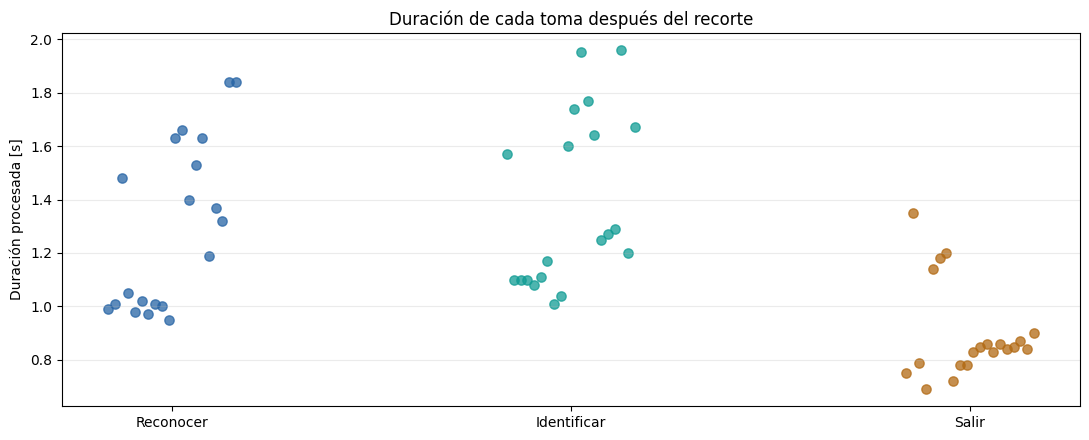

In [3]:
con_salida = [r for r in procesados if r["ruta_procesada"]]
if con_salida:
    fig, ax = plt.subplots(figsize=(11, 4.5))
    colores = ["#2764a5", "#119c94", "#b26a14"]
    for i, comando in enumerate(comandos):
        duraciones = [float(r["duracion_procesada_s"]) for r in con_salida if r["comando"] == comando]
        if duraciones:
            posiciones = i + np.linspace(-.16, .16, len(duraciones))
            ax.scatter(posiciones, duraciones, color=colores[i], alpha=.75, s=45)
    ax.set_xticks(range(3), [c.capitalize() for c in comandos])
    ax.set(ylabel="Duración procesada [s]", title="Duración de cada toma después del recorte")
    ax.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.show()
else:
    print("No hay WAV procesados para graficar.")

## Comparación de una muestra

Cambiar `MUESTRA_ID` por el identificador que se quiera revisar; `None` selecciona la primera captura. Para revisar el caso confirmado por el autor, usar `H002_S001_identificar_0009`.

Los reproductores usan `normalize=False`, para que el navegador no iguale las amplitudes por su cuenta. El gráfico alinea el procesado con el intervalo del original del que proviene. El volumen de reproducción del equipo también influye en la escucha.

Muestra: H001_S001_reconocer_0001
ORIGINAL: 48000 Hz — 3.0 s


Estado: procesado
Avisos: ninguno
Decisión humana: pendiente 
PROCESADO: 16000 Hz — 0.99 s — ganancia: -0.22 dB


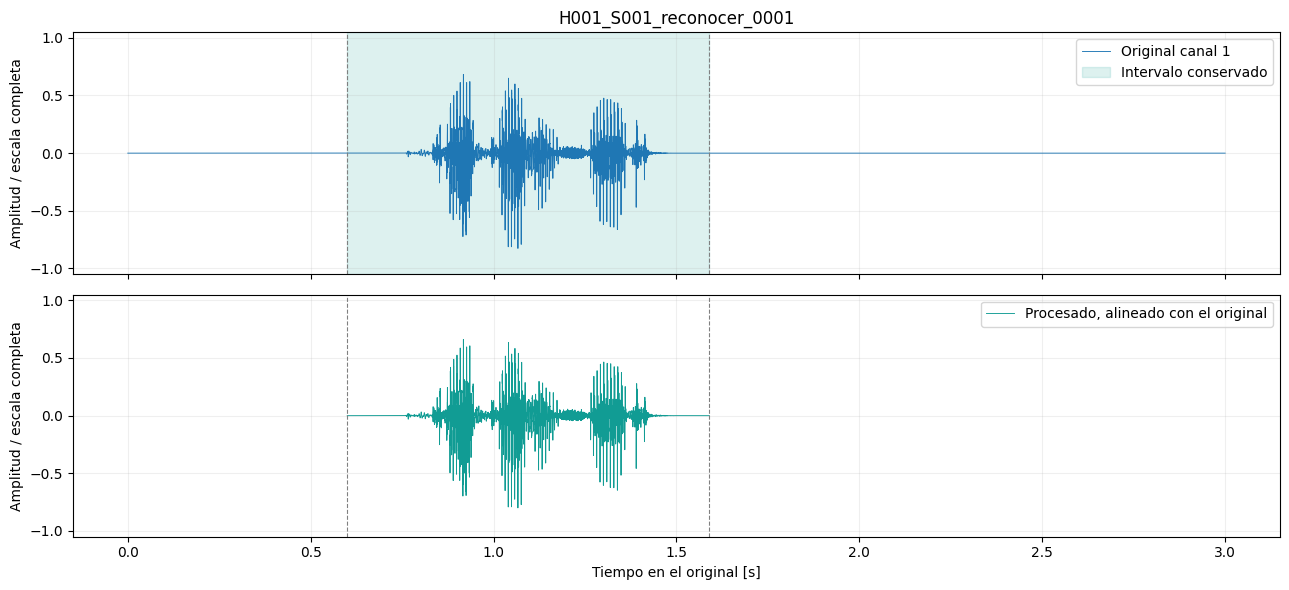

In [4]:
MUESTRA_ID = None
muestra = next((r for r in capturas if r["muestra_id"] == MUESTRA_ID), None) if MUESTRA_ID else (capturas[0] if capturas else None)
if MUESTRA_ID and muestra is None:
    raise ValueError("Ese identificador no aparece en el catálogo de captura.")
if muestra:
    original, fs = leer_wav_pcm16(RAIZ / muestra["ruta_original"])
    x = original.astype(float) / 32768
    r = next((r for r in procesados if r["muestra_id"] == muestra["muestra_id"]), None)
    print("Muestra:", muestra["muestra_id"])
    print("ORIGINAL:", fs, "Hz —", len(x)/fs, "s")
    display(Audio(x[:, 0] if x.shape[1] == 1 else x.T, rate=fs, normalize=False))
    if r:
        print("Estado:", r["estado_procesamiento"])
        print("Avisos:", r["avisos_preprocesamiento"] or "ninguno")
        print("Decisión humana:", r["decision_revision"], r["motivo_revision"])
    if r and r["ruta_procesada"]:
        procesado, fs_p = leer_wav_pcm16(RAIZ / r["ruta_procesada"])
        y = procesado[:, 0].astype(float)/32768
        inicio, fin = float(r["recorte_inicio_s"]), float(r["recorte_fin_s"])
        print("PROCESADO:", fs_p, "Hz —", len(y)/fs_p, "s — ganancia:", round(float(r["ganancia_db"]), 2), "dB")
        display(Audio(y, rate=fs_p, normalize=False))
        fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, sharey=True)
        for canal in range(x.shape[1]):
            axes[0].plot(np.arange(len(x))/fs, x[:, canal], lw=.65, label=f"Original canal {canal+1}")
        axes[0].axvspan(inicio, fin, alpha=.14, color="#119c94", label="Intervalo conservado")
        axes[1].plot(inicio+np.arange(len(y))/fs_p, y, lw=.65, color="#119c94", label="Procesado, alineado con el original")
        for ax in axes:
            ax.axvline(inicio, color="gray", linestyle="--", lw=.8)
            ax.axvline(fin, color="gray", linestyle="--", lw=.8)
            ax.set_ylim(-1.05, 1.05)
            ax.set_ylabel("Amplitud / escala completa")
            ax.grid(alpha=.2)
            ax.legend(loc="upper right")
        axes[0].set_title(muestra["muestra_id"])
        axes[1].set_xlabel("Tiempo en el original [s]")
        plt.tight_layout()
        plt.show()
    else:
        print("Esta captura aún no tiene WAV procesado. Revisar el estado y el JSON de detalle si existe.")

## Integridad y reproducibilidad

Los resultados se versionan por configuración, código y versiones de NumPy/SciPy. Repetir el lote con la misma versión verifica y omite resultados ya confirmados. Un cambio de método produce otra carpeta, conservando las anteriores. `actual.json` señala la versión activa.

Las columnas originales de `metadatos.csv` mantienen su significado; `ruta_procesada` y `estado_procesamiento` apuntan al resultado activo. Los detalles nuevos están en el catálogo de la versión y en un JSON por muestra. La asignación de particiones sigue siendo un paso independiente.

In [5]:
if referencia:
    carpeta = (RAIZ / referencia["ruta_catalogo"]).parent
    procedimiento = json.loads((carpeta / "procedimiento.json").read_text(encoding="utf-8"))
    resumen = json.loads((carpeta / "resumen.json").read_text(encoding="utf-8"))
    print("Versión:", resumen["version"])
    print("Firma:", resumen["firma_procedimiento"])
    print("NumPy / SciPy:", procedimiento["numpy"], procedimiento["scipy"])
    print("Última ejecución: nuevos", resumen["nuevos"], "/ omitidos", resumen["omitidos"])
    print("Configuración:")
    print(json.dumps(procedimiento["configuracion"], indent=2, ensure_ascii=False))

Versión: audio_preprocesamiento_v1_3f3a7a105289
Firma: 3f3a7a105289b16f394a538823ad71b973a35e8c578c5990ebeb41b2b9a7a19b
NumPy / SciPy: 2.3.5 1.17.0
Última ejecución: nuevos 0 / omitidos 60
Configuración:
{
  "version": "audio_preprocesamiento_v1",
  "frecuencia_hz": 16000,
  "quitar_media": true,
  "ventana_ms": 20,
  "salto_ms": 10,
  "percentil_ruido": 20,
  "umbral_fuerte_min_dbfs": -42,
  "umbral_debil_min_dbfs": -48,
  "contraste_fuerte_db": 12,
  "contraste_debil_db": 6,
  "hueco_max_ms": 120,
  "isla_min_ms": 60,
  "actividad_min_ms": 120,
  "margen_ms": 150,
  "borde_aviso_ms": 50,
  "pico_objetivo": 0.8,
  "ganancia_max_db": 6,
  "pico_saturacion": 0.999,
  "fraccion_saturada_aviso": 0.001
}


## Resultados y límites de este hito

En el entorno del asistente (Linux, Python 3.12.14, NumPy 2.3.5 y SciPy 1.17.0), las 60 capturas de desarrollo produjeron 60 WAV: 52 sin avisos y 8 con avisos. Los originales se conservaron idénticos; una segunda ejecución omitió los 60 resultados. Se aprobaron 27 pruebas automáticas de captura y preprocesamiento. No son métricas de reconocimiento.

Los avisos fueron seis picos cercanos al límite original, una amplificación limitada y una actividad próxima al final. El autor confirmó que `H002_S001_identificar_0009` contiene la palabra completa; se conserva su revisión junto al aviso. No se afirma que el asistente haya escuchado todas las grabaciones.

**Revisión local pendiente:** comparar antes y después de los tres comandos para ambos hablantes y de todas las muestras con avisos. Registrar si se conservan consonantes, duración natural y márgenes. El procesamiento de otras personas no debe utilizarse para ajustar el método si están reservadas para prueba final.

Este notebook no implementa extracción definitiva de características ni K-NN. Antes de publicarlo, limpiar las salidas que incrusten voces si ese uso no fue acordado. La documentación del método contiene fuentes, límites y registro del uso de IA generativa.